# Predicción de la posición final de un piloto de Fórmula 1

Alumno: Cristian Sánchez Lagos

## Índice
0. Objetivo del proyecto
1. Obtención de datos
2. Descripción de los datos
3. Exploración y visualización de los datos
4. Preparación de los datos para los algoritmos de Machine Learning
5. Entrenamiento del modelo y comprobación del rendimiento
6. Conclusiones

---
## 0. Objetivo del proyecto

El objetivo de este proyecto es construir un modelo de *Machine Learning* que sea capaz de predecir en qué posición terminará un piloto de F1 usando información disponible antes de que empiece la carrera.

Nuestro *target* a predecir será la posición final del piloto en la carrera (`position`).

Este proyecto se trata de un sistema de **aprendizaje supervisado**, ya que disponemos de datos etiquetados (en este caso son los resultados de las carreras), y a su vez, se trata de un problema de **regresión** porque nuestro valor a predecir se trata de un número.

---
# 1. Obtención de datos

## Fuente
La fuente principal de este proyecto es la **API Ergast**, pero nosotros consultamos los datos a través del repositorio de **TidyTuesday** en GitHub.

## Fuente, recogida de los datos y licencia
- **Fuente original:** base de datos histórica de Fórmula 1 **Ergast** (https://ergast.com/mrd/db/#csv), que recoge resultados de carreras, pilotos, escuderías y circuitos desde 1950.
- **Cómo se obtuvieron:** no son datos medidos por nosotros. Son resultados de carreras compilados en la base Ergast, que publica imágenes completas de la base poco después de cada carrera (en CSV, SQL o mediante API). La documentación consultada no detalla cómo Ergast recopila esos resultados.
- **Nuestros datos:** usamos el repositorio **TidyTuesday**, semana del 7 de septiembre de 2021. El autor descargó el fichero `f1db_csv.zip` de Ergast y aclara que no limpió los datos.
- **Convenciones de los datos:** fechas en formato ISO 8601 y en UTC, valores ausentes marcados como `/N`, y `grid = 0` para las salidas desde el pit lane.
- **Licencia:** los datos de Ergast se publican bajo **Creative Commons Attribution-NonCommercial-ShareAlike 3.0 Unported (CC BY-NC-SA 3.0)**: http://creativecommons.org/licenses/by-nc-sa/3.0/.

## Tablas que usaremos

| Tabla | Qué contiene | Clave |
|---|---|---|
| `results` | Registro por piloto y carrera: parrilla de salida, posición final, puntos, estado | `raceId`, `driverId`, `constructorId`, `statusId` |
| `races` | Información de cada Gran Premio: año, ronda, fecha y circuito | `raceId`, `circuitId` |
| `drivers` | Datos del piloto: nombre y fecha de nacimiento | `driverId` |
| `constructors` | Escuderías | `constructorId` |
| `circuits` | Circuitos: nombre, país y coordenadas | `circuitId` |
| `status` | Motivo por el que acabó la carrera (finalizó, accidente, motor...) | `statusId` |

### Obtenemos los datos

In [100]:
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots

pio.templates.default = "plotly_white"
pd.set_option("display.max_columns", 30)

In [101]:
# Carga de datos
URL_BASE = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2021/2021-09-07/"
TABLAS = ["results", "races", "drivers", "constructors", "circuits", "status"]

def cargar_tabla(nombre):
    return pd.read_csv(f"{URL_BASE}{nombre}.csv", na_values=["\\N"])

datos = {t: cargar_tabla(t) for t in TABLAS}

for nombre, tabla in datos.items():
    print(f"{nombre:13s} {tabla.shape[0]:,} filas · {tabla.shape[1]} columnas")

results       25,220 filas · 18 columnas
races         1,058 filas · 8 columnas
drivers       853 filas · 9 columnas
constructors  211 filas · 5 columnas
circuits      77 filas · 9 columnas
status        137 filas · 2 columnas


## Unimos las tablas en un único DataFrame
Unimos las tablas con `merge` usando los `ids` y nos quedamos con las columnas que nos interesan. También aprovechamos para renombrar algunas tablas.

In [102]:
resultados = datos["results"]
carreras = datos["races"][["raceId", "year", "round", "circuitId", "name", "date"]].rename(columns={"name": "gran_premio"})
pilotos = datos["drivers"][["driverId", "surname", "dob"]].rename(columns={"surname": "piloto", "dob": "nacimiento"})
escuderias = datos["constructors"][["constructorId", "name"]].rename(columns={"name": "escuderia"})
circuitos = datos["circuits"][["circuitId", "name", "country"]].rename(columns={"name": "circuito", "country": "pais"})
estados = datos["status"].rename(columns={"status": "estado"})

f1 = (resultados
      .merge(carreras, on="raceId")
      .merge(escuderias, on="constructorId")
      .merge(circuitos, on="circuitId")
      .merge(pilotos, on="driverId")
      .merge(estados, on="statusId"))

f1 = f1[["raceId", "year", "round", "gran_premio", "date", "circuito", "pais", "escuderia",
         "piloto", "nacimiento", "grid", "position", "positionOrder", "points", "laps", "estado"]]

print(f"DataFrame final: {f1.shape[0]:,} filas · {f1.shape[1]} columnas")
f1.head(10)

DataFrame final: 25,220 filas · 16 columnas


,raceId,year,round,gran_premio,date,circuito,pais,escuderia,piloto,nacimiento,grid,position,positionOrder,points,laps,estado
0,18,2008,1,Australian Grand Prix,2008-03-16,Albert Park Grand Prix Circuit,Australia,McLaren,Hamilton,1985-01-07,1,1.0,1,10.0,58,Finished
1,18,2008,1,Australian Grand Prix,2008-03-16,Albert Park Grand Prix Circuit,Australia,BMW Sauber,Heidfeld,1977-05-10,5,2.0,2,8.0,58,Finished
2,18,2008,1,Australian Grand Prix,2008-03-16,Albert Park Grand Prix Circuit,Australia,Williams,Rosberg,1985-06-27,7,3.0,3,6.0,58,Finished
3,18,2008,1,Australian Grand Prix,2008-03-16,Albert Park Grand Prix Circuit,Australia,Renault,Alonso,1981-07-29,11,4.0,4,5.0,58,Finished
4,18,2008,1,Australian Grand Prix,2008-03-16,Albert Park Grand Prix Circuit,Australia,McLaren,Kovalainen,1981-10-19,3,5.0,5,4.0,58,Finished
5,18,2008,1,Australian Grand Prix,2008-03-16,Albert Park Grand Prix Circuit,Australia,Williams,Nakajima,1985-01-11,13,6.0,6,3.0,57,+1 Lap
6,18,2008,1,Australian Grand Prix,2008-03-16,Albert Park Grand Prix Circuit,Australia,Toro Rosso,Bourdais,1979-02-28,17,7.0,7,2.0,55,Engine
7,18,2008,1,Australian Grand Prix,2008-03-16,Albert Park Grand Prix Circuit,Australia,Ferrari,Räikkönen,1979-10-17,15,8.0,8,1.0,53,Engine
8,18,2008,1,Australian Grand Prix,2008-03-16,Albert Park Grand Prix Circuit,Australia,BMW Sauber,Kubica,1984-12-07,2,NaN,9,0.0,47,Collision
9,18,2008,1,Australian Grand Prix,2008-03-16,Albert Park Grand Prix Circuit,Australia,Toyota,Glock,1982-03-18,18,NaN,10,0.0,43,Accident


Cada fila representa la participación de un piloto en una carrera.

---
# 2. Descripción de los datos

In [103]:
f1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25220 entries, 0 to 25219
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   raceId         25220 non-null  int64  
 1   year           25220 non-null  int64  
 2   round          25220 non-null  int64  
 3   gran_premio    25220 non-null  object 
 4   date           25220 non-null  object 
 5   circuito       25220 non-null  object 
 6   pais           25220 non-null  object 
 7   escuderia      25220 non-null  object 
 8   piloto         25220 non-null  object 
 9   nacimiento     25220 non-null  object 
 10  grid           25220 non-null  int64  
 11  position       14458 non-null  float64
 12  positionOrder  25220 non-null  int64  
 13  points         25220 non-null  float64
 14  laps           25220 non-null  int64  
 15  estado         25220 non-null  object 
dtypes: float64(2), int64(6), object(8)
memory usage: 3.1+ MB


In [104]:
f1.describe()

,raceId,year,round,grid,position,positionOrder,points,laps
count,25220.000000,25220.000000,25220.000000,25220.000000,14458.000000,25220.000000,25220.000000,25220.000000
mean,517.948573,1989.478430,8.263045,11.206582,7.899156,12.934417,1.798178,45.791237
std,290.338036,18.934684,4.857406,7.272450,4.790997,7.744911,4.032883,30.037558
min,1.000000,1950.000000,1.000000,0.000000,1.000000,1.000000,0.000000,0.000000
25%,287.000000,1976.000000,4.000000,5.000000,4.000000,6.000000,0.000000,21.000000
50%,503.000000,1990.000000,8.000000,11.000000,7.000000,12.000000,0.000000,52.000000
75%,762.000000,2006.000000,12.000000,17.000000,11.000000,19.000000,2.000000,66.000000
max,1064.000000,2021.000000,21.000000,34.000000,33.000000,39.000000,50.000000,200.000000


### Observaciones
1. Tenemos 25.220 registros desde 1950 hasta 2021, con 16 columnas.
2. La mayoría de las columnas tienen todos los datos excepto `position` que tiene **14.458 valores**, por lo que **10.762** son nulos. Esto se debe a que son pilotos que no fueron clasificados (abandonos, descalificaciones, u otros motivos).
3. `date` y `nacimiento` se han cargado como texto, así que habrá que convertirlas a fecha.
4. Tenemos registros de épocas muy antiguas, por lo que debemos evitar usar esos datos.
5. `grid = 0` indica salida desde el pit lane.

Los atributos que tenemos en nuestros datos son los siguientes:
| Atributo | Tipo | Descripción |
|---|---|---|
| `raceId` | identificador | Identificador de la carrera |
| `year` | numérico | Año de la temporada |
| `round` | numérico | Número de la carrera dentro de la temporada |
| `gran_premio` | categórico | Nombre del Gran Premio |
| `date` | fecha | Fecha de la carrera |
| `circuito` | categórico | Circuito donde se disputa |
| `pais` | categórico | País del circuito |
| `escuderia` | categórico | Escudería (equipo) del piloto en esa carrera |
| `piloto` | texto | Apellido del piloto |
| `nacimiento` | fecha | Fecha de nacimiento del piloto |
| `grid` | numérico | **Posición de salida en la parrilla.** El valor 0 indica que el piloto salió desde el pit lane (calle de boxes) |
| `position` | numérico | **Posición final oficial.** Está vacía si el piloto no fue clasificado (por ejemplo, por abandono o descalificación) |
| `positionOrder` | numérico | Orden final de la carrera para todos los pilotos, incluidos los que no fueron clasificados |
| `points` | numérico | Puntos obtenidos en la carrera |
| `laps` | numérico | Vueltas completadas |
| `estado` | categórico | Estado final del piloto (finalizó, +1 vuelta, accidente, motor, etc.) |

> Si un piloto que termina *doblado* (con una o más vueltas de retraso) y queda clasificado: aparece con `estado` "+1 Lap" y una `position` válida.

---
# 3. Exploración y visualización de los datos

## 3.1 Temporadas totales y temporadas que usaremos para entrenar al modelo.

In [105]:
f1["date"] = pd.to_datetime(f1["date"])
f1["nacimiento"] = pd.to_datetime(f1["nacimiento"])

carreras_por_anio = f1.groupby("year")["raceId"].nunique().reset_index(name="carreras")
carreras_por_anio["periodo"] = np.where(carreras_por_anio["year"] >= 2014,
                                        "2014-2021 (las que usaremos)", "Resto")

fig = px.bar(carreras_por_anio, x="year", y="carreras", color="periodo",
             color_discrete_map={"2014-2021 (las que usaremos)": "salmon", "Resto": "lightgray"},
             title="Carreras por temporada",
             labels={"year": "Año", "carreras": "Nº de carreras", "periodo": ""})
fig.update_layout()
fig.show()

### Observaciones

1. Hay 897 carreras antes de 2014 y 151 desde 2014. Desde 1950 hasta 2021 han cambiado los coches, el reglamento, el número de pilotos y los equipos, así que nos quedamos únicamente con los datos desde 2014.
2. Los datos llegan solo hasta el 5 de septiembre de 2021, así que 2021 está incompleta (13 carreras).
3. El año 2020 tuvo 17 carreras debido a la pandemia.

Nos quedamos únicamente con los datos a partir de la temporada 2014

In [106]:
f1 = f1[f1["year"] >= 2014].copy()
print(f"{f1.shape[0]:,} filas · {f1['raceId'].nunique()} carreras · "
      f"{f1['circuito'].nunique()} circuitos · {f1['escuderia'].nunique()} escuderías · {f1['piloto'].nunique()} pilotos")

3,087 filas · 151 carreras · 28 circuitos · 19 escuderías · 51 pilotos


## 3.2 Valores nulos y estado final de los pilotos

In [107]:
f1.isnull().sum()

,0
raceId,0
year,0
round,0
gran_premio,0
date,0
circuito,0
pais,0
escuderia,0
piloto,0
nacimiento,0


Podemos observar que tenemos 530 pilotos que no han clasificado, ahora estudiaremos sus motivos:

In [108]:
# ¿Cómo han terminado los pilotos?
f1["clasificado"] = f1["position"].notna()

print(f1["clasificado"].value_counts())
print(f"\nMotivos por los que un piloto no terminó la carrera:")
print(f1.loc[~f1["clasificado"], "estado"].value_counts().head(10))

clasificado
True     2557
False     530
Name: count, dtype: int64

Motivos por los que un piloto no terminó la carrera:
estado
Collision           104
Engine               56
Accident             53
Brakes               37
Retired              34
Power Unit           31
Collision damage     27
Gearbox              24
Suspension           18
Electrical           13
Name: count, dtype: int64


In [109]:
fig = make_subplots(rows=1, cols=2, column_widths=[0.4, 0.6],
                    subplot_titles=("Pilotos clasificados y no clasificados", "Top 10 motivos de no clasificación"))

conteo_clas = f1["clasificado"].value_counts()
etiquetas = ["Clasificado" if v else "No clasificado" for v in conteo_clas.index]
fig.add_trace(go.Bar(x=etiquetas, y=conteo_clas.values, text=conteo_clas.values, textposition="outside",
                     marker_color=["skyblue" if v else "salmon" for v in conteo_clas.index]), row=1, col=1)

motivos = f1.loc[~f1["clasificado"], "estado"].value_counts().head(10).sort_values()
fig.add_trace(go.Bar(x=motivos.values, y=motivos.index, orientation="h", text=motivos.values,
                     textposition="outside", marker_color="salmon"), row=1, col=2)
fig.update_xaxes(title_text="Nº de casos", row=1, col=2)
fig.update_layout(showlegend=False, height=420)
fig.show()

In [110]:
# ¿Cuántos pilotos han salido desde el pit lane?
print("Pilotos que salieron desde el pit lane (grid = 0):", (f1["grid"] == 0).sum())

Pilotos que salieron desde el pit lane (grid = 0): 34


### Observaciones

1. En el periodo 2014-2021 tenemos 3.087 registros. La única columna con nulos es `position` con 530 pilotos (17,2 %) que no terminaron la carrera.
2. Los motivos principales son colisiones (104), problemas de motor (56), accidentes (53) y frenos (37). Esto son sucesos imprevisibles por lo que no debemos tenerlo en cuenta.
3. Los 2.557 pilotos clasificados (82,8 %) incluyen a los que terminan con vueltas de retraso, que sí tienen `position`.
4. Hay 34 salidas desde el pit lane (`grid = 0`).

Tras observar los datos, hemos decidido que el modelo se entrenará solo con los pilotos que terminen la carrera.

## 3.3 Distribuciones de la parrilla y de la posición final

In [111]:
clasificados = f1[f1["clasificado"]].copy()

fig = make_subplots(rows=1, cols=2, subplot_titles=("Posición de salida (grid)", "Posición final (solo clasificados)"))
fig.add_trace(go.Histogram(x=f1["grid"], xbins=dict(start=-0.5, end=23.5, size=1), marker_color="steelblue"), row=1, col=1)
fig.add_trace(go.Histogram(x=clasificados["position"], xbins=dict(start=0.5, end=23.5, size=1), marker_color="salmon"), row=1, col=2)
fig.update_xaxes(title_text="Posición de parrilla", row=1, col=1)
fig.update_xaxes(title_text="Posición final", row=1, col=2)
fig.update_yaxes(title_text="Nº de pilotos", row=1, col=1)
fig.update_layout(showlegend=False, height=400, bargap=0.05)
fig.show()

### Observaciones

1. Parrilla: desde la posición 1 a la 19 tenemos unos 150 registros aprox. (una por carrera ya que hay 151 carreras). A partir de la posición 20 hay menos datos, porque no todas las temporadas han tenido 22 coches.
La barra del 0 son los pilotos del pit lane.
2. Posición final: desde la posición 1 a la 12 tienen casi 151 casos cada una, pero desde la 13 la frecuencia va bajando. Esto se debe a que si hay muchos abandonos, pocos coches llegan a las últimas posiciones.
3. Como consecuencia, tenemos menos ejemplos de posiciones finales bajas y el modelo las conocerá peor.
4. La posición final media de los clasificados es 9,1.

## 3.4 Relación entre la parrilla y la posición final

In [112]:
salida_normal = clasificados[clasificados["grid"] > 0]
rng = np.random.default_rng(42)

media_por_parrilla = salida_normal.groupby("grid")["position"].mean()

fig = go.Figure()
fig.add_trace(go.Scatter(
    x=salida_normal["grid"] + rng.uniform(-0.3, 0.3, len(salida_normal)),
    y=salida_normal["position"] + rng.uniform(-0.3, 0.3, len(salida_normal)),
    mode="markers", marker=dict(size=5, opacity=0.2, color="steelblue"),
    name="Pilotos", hoverinfo="skip"))
fig.add_trace(go.Scatter(x=media_por_parrilla.index, y=media_por_parrilla.values, mode="lines+markers",
                         line=dict(color="red"), name="Media de la posición final"))
fig.add_trace(go.Scatter(x=[1, 22], y=[1, 22], mode="lines",
                         line=dict(color="black", dash="dash"), name="Termina donde sale"))
fig.update_layout(title="Posición de salida vs posición final",
                  xaxis_title="Posición de salida", yaxis_title="Posición final",
                  width=800, height=650)
fig.show()

### Observaciones

1. Existe una relación clara y creciente: salir más atrás suele implicar terminar más atrás.
2. Quien sale primero termina de media en la posición 2, pero quien sale 20º termina de media en la 13,9, no en la 20ª. Este efecto se conoce cómo "regresión a la media": desde atrás es fácil adelantar a coches lentos o que abandonan, y desde la pole solo se puede perder.
3. De los 139 pilotos que salieron en la pole, el 56,8 % ganó la carrera.
4. La nube de puntos es ancha debido a que desde una misma casilla de salida se puede terminar varias posiciones por delante o por detrás.

## 3.5 La escudería

In [114]:
conteo = clasificados["escuderia"].value_counts()
suficientes = conteo[conteo >= 60].index
datos_esc = clasificados[clasificados["escuderia"].isin(suficientes)]
orden = datos_esc.groupby("escuderia")["position"].median().sort_values().index

fig = px.box(datos_esc, y="escuderia", x="position", orientation="h",
             category_orders={"escuderia": list(orden)},
             color_discrete_sequence=["lightsalmon"],
             title="Posición final por escudería (2014-2021)",
             labels={"position": "Posición final", "escuderia": ""})
fig.update_yaxes(autorange="reversed")
fig.update_layout(height=600)
fig.show()

### Observaciones

1. En estos datos podemos observar que la escudería sí que importa. Podemos ver que la posición media de un coche Mercedes es la 2ª posición, Ferrari y Red Bull comparten de media la 4ª posición, Force India 8ª, Racing Point y McLaren 9ª, etc.
2. Mercedes tiene la caja más estrecha, esto significa que gana y termina arriba de forma muy constante. Los equipos de la zona media tienen cajas mucho más anchas, es decir, resultados más variables.
3. En el gráfico aparecen las escuderías con al menos 60 resultados clasificados.
4. Algunas escuderías cambian de nombre, por lo que para el modelo serán escuderías distintas.

In [115]:
# Posición final media de cada escudería en cada temporada.
tabla = datos_esc.pivot_table(index="escuderia", columns="year", values="position", aggfunc="mean")
tabla = tabla.loc[orden]

fig = px.imshow(tabla, text_auto=".1f", color_continuous_scale="RdYlGn_r", aspect="auto",
                title="Posición final media por escudería y temporada (verde = mejor)",
                labels=dict(x="Temporada", y="", color="Posición final media"))
fig.update_xaxes(type="category")
fig.update_layout(height=600)
fig.show()

### Observaciones

1. El rendimiento de las escuderías pueden cambiar de una temporada a otra, esto significa, que el rendimiento no es una constante.
Por ejemplo:
  - Williams ha empeorado año tras año, de ser ≈6º, ha pasado a ser 16º en 2019.
  - McLaren en cambio, ha tenido una mejora y ha pasado del 12º puesto en 2015, al 7º en 2021.

## 3.6 El circuito

Ahora vamos a comprobar si el circuito influye en la posición final de un piloto. Para ello, vamos a comprobar cuántas posiciones gana o pierde de media el pelito respecto a su posición de salida.

In [116]:
salida_normal = salida_normal.assign(ganadas=salida_normal["grid"] - salida_normal["position"])

conteo_circ = salida_normal["circuito"].value_counts()
circ_ok = conteo_circ[conteo_circ >= 40].index
por_circuito = (salida_normal[salida_normal["circuito"].isin(circ_ok)]
                .groupby("circuito")["ganadas"].mean().sort_values())
media_global = salida_normal["ganadas"].mean()

datos_circ = por_circuito.reset_index()
datos_circ["respecto a la media"] = np.where(datos_circ["ganadas"] > media_global, "Por encima", "Por debajo")

fig = px.bar(datos_circ, x="ganadas", y="circuito", orientation="h", color="respecto a la media",
             color_discrete_map={"Por encima": "seagreen", "Por debajo": "salmon"},
             title="Posiciones ganadas de media respecto a la salida, por circuito",
             labels={"ganadas": "Posiciones ganadas", "circuito": "", "respecto a la media": ""})
fig.add_vline(x=media_global, line_dash="dash", line_color="black",
              annotation_text=f"Media global ({media_global:.2f})", annotation_position="top")
fig.update_layout(height=700)
fig.show()

### Observaciones
1. Todos los circuitos están por encima de cero ya que no se tienen en cuenta los pilotos que han abandonado, por lo que los pilotos suben sus posiciones. La media es de aprox. 1 posicion ganada por circuito.
2. Analizando los circuitos, podemos observar que en el que menos posiciones se gana es en Paul Ricard, y donde más se gana es en el Circuito de las Americas. Un posible motivo de estos datos (aunque no se pueden demostrar) es que en circuitos que ocurran muchos incidentes de carrera o abandonos altera el orden final.
3. La diferencia entre la última carrera y la primera es de unas 2 posiciones. El efecto que tiene el circuito en el resultado final de una carrera parece ser menor en comparación con el de la posición de salida y la escudería.

## 3.7 Correlaciones

In [117]:
numericas = salida_normal[["grid", "position", "year", "round"]]
corr_matrix = numericas.corr()

fig = px.imshow(corr_matrix, text_auto=".2f", color_continuous_scale="RdBu_r",
                zmin=-1, zmax=1, title="Matriz de correlación")
fig.update_layout(height=480, width=560)
fig.show()

corr_matrix["position"].sort_values(ascending=False)

,position
position,1.000000
grid,0.758586
round,0.025513
year,0.005918


### Observaciones

1. La parrilla es lo que más se relaciona con la posición final: correlación de 0,76.
2. `year` y `round` apenas se relacionan con la posición final, así que no esperamos que mejoren el modelo por sí solas.
3. Esta matriz sólo mide relaciones entre variables numéricas. El efecto de las variables categóricas ya se analizó anteriormente.

---
# 4. Preparación de los datos para los algoritmos de Machine Learning

## 4.1 Limpieza
- Nos quedamos con los pilotos que han clasificado.
- Los pilotos que salen desde el pit lane (`grid = 0`) en realidad salen detrás de toda la parrilla. Le asignamos la última posición de su carrera + 1.

In [118]:
df = f1[f1["clasificado"]].copy()
df["pos_final"] = df["position"].astype(int)

ultima_parrilla = df.groupby("raceId")["grid"].transform("max")
df["grid_aj"] = np.where(df["grid"] == 0, ultima_parrilla + 1, df["grid"])

## 4.2 Feature engineering

Atributos candidatos:
- `edad`: edad del piloto el día de la carrera, en años.
- `experiencia`: carreras que ha disputado el piloto desde 2014 antes de la actual (hayan terminado o no).
- `participantes`: pilotos con resultado registrado en esa carrera (22, 20, 18...), terminen o no.
- `grid_relativo`: posición de salida dividida entre los participantes (cerca de 0 es la pole, 1 es el último). Sirve para comparar parrillas de distinto tamaño.

In [119]:
df["edad"] = (df["date"] - df["nacimiento"]).dt.days / 365.25

f1_ordenado = f1.sort_values("date")
df["experiencia"] = f1_ordenado.groupby(["piloto", "nacimiento"]).cumcount()

df["participantes"] = df["raceId"].map(f1.groupby("raceId").size())

df["grid_relativo"] = df["grid_aj"] / df["participantes"]

In [120]:
new_attributes = ["edad", "experiencia", "participantes", "grid_relativo"]
df[new_attributes].describe()

,edad,experiencia,participantes,grid_relativo
count,2557.000000,2557.000000,2557.000000,2557.000000
mean,27.587263,51.614392,20.475948,0.511330
std,5.178847,40.076667,0.923475,0.292680
min,17.492129,0.000000,18.000000,0.045455
25%,23.488022,17.000000,20.000000,0.250000
50%,26.740589,42.000000,20.000000,0.500000
75%,31.216975,80.000000,22.000000,0.750000
max,41.867214,150.000000,22.000000,1.050000


### Observaciones
1. La edad de los pilotos va de unos 17,5 a 42 años (media de 27,6) y la experiencia de 0 a 150 carreras (media de 51,6). Ojo con la experiencia: solo cuenta las carreras desde 2014, así que un veterano en 2014 aparece con 0.
2. `participantes` vale 18, 20 o 22 (la mayoría de carreras tienen 20). Como casi no varía, `grid_relativo` es muy parecido a la parrilla: va de 0,05 a 1,05 con media de 0,51.

Vemos las correlaciones con la posición final.

In [121]:
columnas_corr = ["grid_aj", "year", "round"] + new_attributes + ["pos_final"]
corr_matrix = df[columnas_corr].corr()
corr_matrix["pos_final"].sort_values(ascending=False)

,pos_final
pos_final,1.000000
grid_aj,0.757443
grid_relativo,0.753314
participantes,0.058748
round,0.023607
year,0.012582
edad,-0.193175
experiencia,-0.260989


In [122]:
corr_matrix.loc[new_attributes, ["grid_aj", "year", "edad", "experiencia", "participantes", "grid_relativo"]].round(2)

,grid_aj,year,edad,experiencia,participantes,grid_relativo
edad,-0.20,0.03,1.00,0.47,-0.02,-0.20
experiencia,-0.27,0.62,0.47,1.00,-0.32,-0.25
participantes,0.06,-0.50,-0.02,-0.32,1.00,-0.01
grid_relativo,1.00,0.03,-0.20,-0.25,-0.01,1.00


### Observaciones
1. La parrilla sigue siendo lo que más se relaciona con la posición final (**0,76**).
2. `participantes` (0,06) apenas se relaciona con el objetivo. `round` (0,02) y `year` (0,01) tampoco.

**Decisión:** borramos los cuatro atributos nuevos y nos quedamos con **parrilla + circuito + escudería**.

## 4.3 Conversión de categorías a números (one-hot)
`circuito` y `escuderia` no tienen un orden natural, así que usamos **one-hot encoding**.

In [123]:
NUMERICAS = ["grid_aj", "pos_final"]
CATEGORICAS = ["circuito", "escuderia"]

df = df[NUMERICAS + CATEGORICAS]

df = pd.get_dummies(df, columns=CATEGORICAS, dtype=int)
df.head(5)

,grid_aj,pos_final,circuito_Albert Park Grand Prix Circuit,circuito_Autodromo Enzo e Dino Ferrari,circuito_Autodromo Internazionale del Mugello,circuito_Autodromo Nazionale di Monza,circuito_Autódromo Hermanos Rodríguez,circuito_Autódromo Internacional do Algarve,circuito_Autódromo José Carlos Pace,circuito_Bahrain International Circuit,circuito_Baku City Circuit,circuito_Circuit Gilles Villeneuve,circuito_Circuit Park Zandvoort,circuito_Circuit Paul Ricard,circuito_Circuit de Barcelona-Catalunya,...,escuderia_Caterham,escuderia_Ferrari,escuderia_Force India,escuderia_Haas F1 Team,escuderia_Lotus F1,escuderia_Manor Marussia,escuderia_Marussia,escuderia_McLaren,escuderia_Mercedes,escuderia_Racing Point,escuderia_Red Bull,escuderia_Renault,escuderia_Sauber,escuderia_Toro Rosso,escuderia_Williams
22127,3,1,1,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
22128,4,2,1,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0
22129,10,3,1,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0
22130,5,4,1,0,0,0,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0
22131,15,5,1,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1


## 4.4 Mezcla y separación en entrenamiento y test

In [124]:
from sklearn.model_selection import train_test_split

df = df.sample(frac=1, random_state=42)

X = df.drop("pos_final", axis=1)
y = df["pos_final"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Si todo es correcto, la distribución de los datos de entrenamiento y de test debe ser similar.

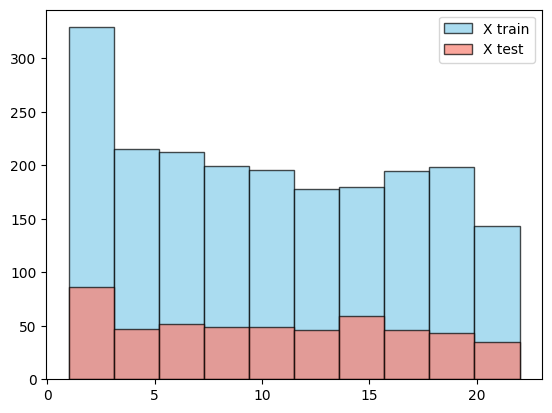

In [125]:
import matplotlib.pyplot as plt

X_train["grid_aj"].hist(edgecolor="black", label="X train", color="skyblue", alpha=0.7)
X_test["grid_aj"].hist(edgecolor="black", label="X test", color="salmon", alpha=0.7)

plt.legend()
plt.grid(visible=False)
plt.show()

---
# 6. Entrenamiento del modelo y comprobación del rendimiento

## 6.1 Función de evaluación y líneas base

In [126]:
from sklearn.model_selection import cross_validate
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

resultados_cv = []

def evaluar_cv(modelo, nombre, cv=5):
    puntuaciones = cross_validate(
        modelo, X_train, y_train, cv=cv,
        scoring={"rmse": "neg_root_mean_squared_error",
                 "mae": "neg_mean_absolute_error",
                 "r2": "r2"},
    )

    resultado = {
        "Modelo": nombre,
        "RMSE CV": -puntuaciones["test_rmse"].mean(),
        "MAE CV": -puntuaciones["test_mae"].mean(),
        "R² CV": puntuaciones["test_r2"].mean(),
    }

    print(f"{nombre}: RMSE={resultado['RMSE CV']:.2f} · MAE={resultado['MAE CV']:.2f} · R²={resultado['R² CV']:.3f}")
    resultados_cv.append(resultado)

    return resultado

## 6.2 Regresión lineal

In [128]:
from sklearn.linear_model import LinearRegression

model_lineal = LinearRegression()
evaluar_cv(model_lineal, "Regresión lineal");

Regresión lineal: RMSE=2.99 · MAE=2.28 · R²=0.652


## 6.3 Árbol de decisión

In [129]:
from sklearn.tree import DecisionTreeRegressor

model_tree = DecisionTreeRegressor(random_state=42)
evaluar_cv(model_tree, "Árbol de decisión");

Árbol de decisión: RMSE=3.88 · MAE=2.90 · R²=0.417


## 6.4 Random Forest

In [130]:
from sklearn.ensemble import RandomForestRegressor

model_forest = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
evaluar_cv(model_forest, "Random Forest");

Random Forest: RMSE=3.23 · MAE=2.43 · R²=0.595


## 6.5 Ajuste de hiperparámetros del Random Forest
Probamos varias combinaciones de `max_depth` (profundidad máxima) y `min_samples_leaf` (mínimo de muestras por hoja) con `GridSearchCV`. Limitar la profundidad y exigir más muestras por hoja evita que los árboles memoricen los datos de entrenamiento.

In [131]:
from sklearn.model_selection import GridSearchCV

rejilla = {
    "n_estimators": [100, 200],
    "max_depth": [None, 6, 10],
    "min_samples_leaf": [1, 10, 25],
}

busqueda = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_grid=rejilla, cv=5,
    scoring="neg_root_mean_squared_error", n_jobs=1,
)

busqueda.fit(X_train, y_train)

print("Mejores hiperparámetros:", busqueda.best_params_)
print(f"RMSE CV durante la búsqueda: {-busqueda.best_score_:.3f}")

Mejores hiperparámetros: {'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 200}
RMSE CV durante la búsqueda: 3.069


In [132]:
model_forest_ajustado = RandomForestRegressor(**busqueda.best_params_, random_state=42, n_jobs=-1)
evaluar_cv(model_forest_ajustado, "Random Forest ajustado");

Random Forest ajustado: RMSE=3.07 · MAE=2.33 · R²=0.635


## 6.5 Gradient Boosting Regressor

Gradient Boosting construye una serie de árboles de decisión de forma secuencial. Cada nuevo árbol intenta corregir los errores cometidos por los anteriores.

In [133]:
from sklearn.ensemble import GradientBoostingRegressor

model_gradient = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

evaluar_cv(model_gradient, "Gradient Boosting");

Gradient Boosting: RMSE=2.99 · MAE=2.30 · R²=0.652


## 6.6 KNN Regressor

KNN (K-Nearest Neighbors) es un algoritmo basado en la proximidad entre observaciones.

Para realizar una predicción, busca los K vecinos más cercanos dentro del conjunto de entrenamiento y calcula una predicción a partir de sus valores.

En este proyecto, buscará carreras similares teniendo en cuenta la posición de salida, el circuito y la escudería.

Necesita escalado para evitar que las variables con magnitudes mayores dominen el cálculo de distancias.

In [134]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

preprocesador_knn = ColumnTransformer(
    transformers=[
        ("escalado", StandardScaler(), ["grid_aj"])
    ],
    remainder="passthrough"
)

model_knn = make_pipeline(
    preprocesador_knn,
    KNeighborsRegressor(
        n_neighbors=15,
        weights="distance",
        p=2
    )
)

evaluar_cv(model_knn, "KNN Regressor");

KNN Regressor: RMSE=3.37 · MAE=2.54 · R²=0.559


## 6.6 Comparación de modelos

In [135]:
tabla_resultados = pd.DataFrame(resultados_cv).sort_values("RMSE CV").reset_index(drop=True)
display(tabla_resultados.round(3))

fig = px.bar(tabla_resultados.sort_values("RMSE CV", ascending=False),
             x="RMSE CV", y="Modelo", orientation="h", text_auto=".2f",
             title="RMSE por validación cruzada (menor es mejor)",
             labels={"RMSE CV": "RMSE (posiciones)", "Modelo": ""})
fig.update_traces(marker_color="steelblue")
fig.update_layout(height=380)
fig.show()

,Modelo,RMSE CV,MAE CV,R² CV
0,Regresión lineal,2.994,2.285,0.652
1,Gradient Boosting,2.994,2.301,0.652
2,Random Forest ajustado,3.069,2.326,0.635
3,Random Forest,3.233,2.427,0.595
4,KNN Regressor,3.371,2.539,0.559
5,Árbol de decisión,3.881,2.897,0.417
6,Posición final = parrilla,4.180,3.002,0.327
7,Posición media,5.096,4.362,-0.004


### Observaciones

1. El mejor modelo es la regresión lineal: RMSE de 2,99, MAE de 2,29 y R² de 0,65.

2. El Gradient Boosting Regressor obtiene exactamente el mismo RMSE y R² que la regresión lineal (2,99 y 0,65), aunque presenta un MAE ligeramente superior (2,30 frente a 2,29). Por tanto, no consigue mejorar el modelo lineal.

3. El Random Forest ajustado (max_depth=10, n_estimators=200) mejora al Random Forest por defecto (3,07 frente a 3,23).

4. El KNN Regressor obtiene un RMSE de 3,37, un MAE de 2,54 y un R² de 0,56. Su rendimiento es inferior al de los modelos anteriores, lo que sugiere que buscar carreras similares mediante distancias no es la estrategia más eficaz con las variables actuales.

5. El árbol de decisión por defecto sigue siendo el peor modelo supervisado (3,88).

## 6.7 Evaluación final sobre el conjunto de test
Elegimos el mejor **modelo entrenable** según el RMSE de validación cruzada, lo entrenamos con todo el conjunto de entrenamiento y lo evaluamos **una sola vez** con el test.

In [136]:
modelos = {
    "Regresión lineal": model_lineal,
    "Árbol de decisión": model_tree,
    "Random Forest": model_forest,
    "Random Forest ajustado": model_forest_ajustado,
    "Gradient Boosting": model_gradient,
    "KNN Regressor": model_knn,
}

candidatos = tabla_resultados[
    tabla_resultados["Modelo"].isin(modelos.keys())
].reset_index(drop=True)

nombre_final = candidatos.loc[0, "Modelo"]
modelo_final = modelos[nombre_final]

modelo_final.fit(X_train, y_train)

print("Modelo seleccionado:", nombre_final)

Modelo seleccionado: Regresión lineal


In [139]:
y_pred_test = modelo_final.predict(X_test)

predicciones = f1.loc[
    X_test.index,
    ["year", "round", "gran_premio", "piloto", "escuderia", "circuito"]
].copy()

predicciones["grid_aj"] = X_test["grid_aj"]

predicciones["pos_real"] = y_test
predicciones["pos_predicha"] = y_pred_test

predicciones["error"] = predicciones["pos_predicha"] - predicciones["pos_real"]
predicciones["error_abs"] = predicciones["error"].abs()

display(
    predicciones.head(20).style.format({
        "pos_predicha": "{:.2f}",
        "error": "{:+.2f}",
        "error_abs": "{:.2f}"
    })
)

,year,round,gran_premio,piloto,escuderia,circuito,grid_aj,pos_real,pos_predicha,error,error_abs
23702,2017,17,United States Grand Prix,Ocon,Force India,Circuit of the Americas,6,6,6.21,+0.21,0.21
22920,2016,1,Australian Grand Prix,Sainz,Toro Rosso,Albert Park Grand Prix Circuit,7,9,7.65,-1.35,1.35
23151,2016,11,Hungarian Grand Prix,Ericsson,Sauber,Hungaroring,22,20,15.93,-4.07,4.07
23494,2017,7,Canadian Grand Prix,Hamilton,Mercedes,Circuit Gilles Villeneuve,1,1,2.01,+1.01,1.01
24718,2020,5,70th Anniversary Grand Prix,Latifi,Williams,Silverstone Circuit,18,19,13.92,-5.08,5.08
23568,2017,10,British Grand Prix,Magnussen,Haas F1 Team,Silverstone Circuit,16,12,14.48,+2.48,2.48
23688,2017,16,Japanese Grand Prix,Palmer,Renault,Suzuka Circuit,18,12,13.36,+1.36,1.36
23768,2017,20,Abu Dhabi Grand Prix,Vandoorne,McLaren,Yas Marina Circuit,13,12,10.31,-1.69,1.69
23660,2017,15,Malaysian Grand Prix,Vettel,Ferrari,Sepang International Circuit,20,4,10.79,+6.79,6.79
23820,2018,3,Chinese Grand Prix,Hamilton,Mercedes,Shanghai International Circuit,4,4,3.78,-0.22,0.22


## 6.10 Predicción de situaciones nuevas
Planteamos tres situaciones hipotéticas y vemos qué posición final estima el modelo. Como no son carreras reales, no podemos calcular el error.

In [142]:
nuevos = pd.DataFrame([
    {"grid_aj": 1,  "circuito": "Circuit de Monaco",                 "escuderia": "Mercedes"},
    {"grid_aj": 1,  "circuito": "Autodromo Nazionale di Monza",      "escuderia": "Williams"},
    {"grid_aj": 15, "circuito": "Autodromo Nazionale di Monza",      "escuderia": "Red Bull"},
    {"grid_aj": 15, "circuito": "Autodromo Nazionale di Monza",      "escuderia": "Haas F1 Team"},
], index=["Pole con Mercedes en Mónaco", "Pole con Williams en Monza",
          "Salida 15ª con Red Bull en Monza", "Salida 15ª con Haas en Monza"])

X_nuevos = pd.get_dummies(nuevos, columns=CATEGORICAS, dtype=int).reindex(columns=X_train.columns, fill_value=0)
resultado = nuevos[["grid_aj"]].rename(columns={"grid_aj": "Parrilla"}).copy()
resultado["Posición final estimada"] = modelo_final.predict(X_nuevos).round(1)
display(resultado)

,Parrilla,Posición final estimada
Pole con Mercedes en Mónaco,1,1.5
Pole con Williams en Monza,1,6.8
Salida 15ª con Red Bull en Monza,15,8.9
Salida 15ª con Haas en Monza,15,14.2


---
# 7. Conclusiones

Mis conclusiones de este ejercicio es que únicamente con la parrilla, circuito y escudería se puede estimar la posición final de un piloto con cierta fiabilidad, sin tener en cuenta casuísticas raras.
Respecto al modelo, me ha sorprendido que otros algoritmos más pesados como podían ser el KNN o Gradient Boosting no funcionen mejor frente a este problema, y si lo haga un algoritmo tradicional como la regresión lineal.